In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
PROCESSED = '../02_Data/processed/'
listings = pd.read_csv(PROCESSED + 'listings_clean.csv')
neighbourhoods = pd.read_csv(PROCESSED + 'neighbourhoods_clean.csv')

print(f"Total rows: {len(listings):,}")
print(f"Distinct listing IDs: {listings['id'].nunique():,}")

C:\Users\Admin\AppData\Local\Temp\ipykernel_22592\2417504780.py:8: DtypeWarning: Columns (24,31,32) have mixed types. Specify dtype option on import or set low_memory=False.
  listings = pd.read_csv(PROCESSED + 'listings_clean.csv')


Total rows: 15,293
Distinct listing IDs: 15,293


,Metric,Count,% of total
0,Total rows,15293,100.00
1,Distinct listing IDs,15293,100.00
2,Missing price,1938,12.67
3,Zero / negative price,0,0.00
4,Missing room_type,0,0.00
5,Missing neighbourhood,0,0.00
6,Missing host_is_superhost,87,0.57



Room Type Composition


,% of listings
room_type,
Entire home/apt,70.91
Private room,27.87
Shared room,0.78
Hotel room,0.44


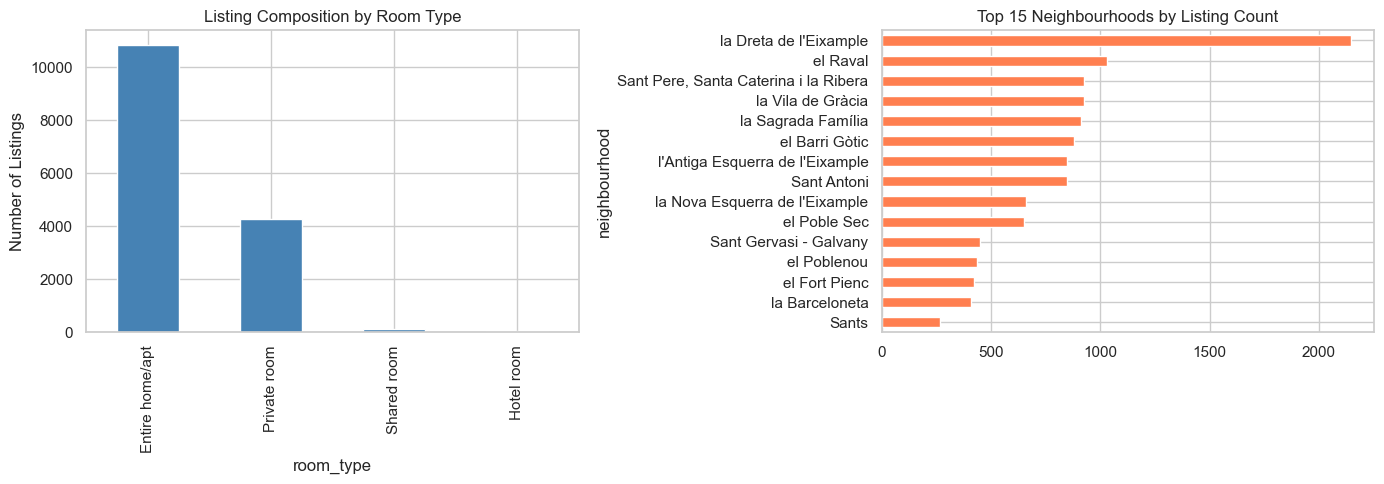

In [8]:
# Population profile
profile = pd.DataFrame({
    'Metric': [
        'Total rows',
        'Distinct listing IDs',
        'Missing price',
        'Zero / negative price',
        'Missing room_type',
        'Missing neighbourhood',
        'Missing host_is_superhost'
    ],
    'Count': [
        len(listings),
        listings['id'].nunique(),
        listings['price'].isna().sum(),
        (listings['price'] <= 0).sum(),
        listings['room_type'].isna().sum(),
        listings['neighbourhood'].isna().sum(),
        listings['host_is_superhost'].isna().sum()
    ]
})
profile['% of total'] = (profile['Count'] / len(listings) * 100).round(2)
display(profile)

# Room type composition
room_mix = listings["room_type"].value_counts(normalize = True).mul(100).round(2)
print("\nRoom Type Composition")
display(room_mix.to_frame('% of listings'))

# Chart
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

listings['room_type'].value_counts().plot(kind='bar', ax=ax[0], color='steelblue')
ax[0].set_title('Listing Composition by Room Type')
ax[0].set_ylabel('Number of Listings')

listings['neighbourhood'].value_counts().head(15).plot(kind='barh', ax=ax[1], color='coral')
ax[1].set_title('Top 15 Neighbourhoods by Listing Count')
ax[1].invert_yaxis()

plt.tight_layout()
plt.show()

In [9]:
# Data-driven quantile segments
prices = listings['price'].dropna()
q25, q50, q75 = prices.quantile([0.25, 0.50, 0.75])
print(f"Q25 = €{q25:.0f}, Median = €{q50:.0f}, Q75 = €{q75:.0f}")

def price_segment(p):
    if pd.isna(p): return 'Unknown'
    if p < q25:   return 'Budget'
    if p < q50:   return 'Lower-Mid'
    if p < q75:   return 'Upper-Mid'
    return 'Premium'

listings['price_segment'] = listings['price'].apply(price_segment)

# Segment composition
seg_summary = listings.groupby('price_segment').agg(
    listings=('id', 'count'),
    median_price=('price', 'median'),
    mean_price=('price', 'mean'),
    median_accommodates=('accommodates', 'median'),
    median_min_nights=('minimum_nights', 'median'),
    pct_superhost=('host_is_superhost', lambda s: round(s.mean()*100, 1))
).round(1)

print("\n--- Price Segment Summary ---")
display(seg_summary.sort_values('median_price'))

# Room-type composition per segment
seg_room = pd.crosstab(listings['price_segment'], listings['room_type'], normalize='index').mul(100).round(1)
print("\n--- Room Type Composition by Segment (%) ---")
display(seg_room)



Q25 = €89, Median = €178, Q75 = €286

--- Price Segment Summary ---


,listings,median_price,mean_price,median_accommodates,median_min_nights,pct_superhost
price_segment,,,,,,
Budget,3339,55.9,55.1,2.0,32.0,20.2
Lower-Mid,3338,131.0,131.5,3.0,31.0,22.5
Upper-Mid,3332,230.0,230.8,4.0,2.0,33.5
Premium,3346,378.9,544.4,6.0,1.0,35.1
Unknown,1938,NaN,NaN,2.0,3.0,12.3



--- Room Type Composition by Segment (%) ---


room_type,Entire home/apt,Hotel room,Private room,Shared room
price_segment,,,,
Budget,41.8,0.0,55.5,2.7
Lower-Mid,74.4,0.6,25.0,0.1
Premium,96.0,0.4,3.4,0.1
Unknown,37.7,0.3,60.9,1.1
Upper-Mid,90.7,0.8,8.4,0.0


In [10]:
print("TOP 5 NEIGHBOURHOODS PER SEGMENT")

for seg in ['Budget', 'Lower-Mid', 'Upper-Mid', 'Premium']:
    subset = listings.loc[listings['price_segment'] == seg, 'neighbourhood']
    top = subset.dropna().value_counts().head(5)
    
    if top.empty:
        print(f"\n{seg} [{len(subset)} listings]: no data")
    else:
        print(f"\n{seg} [{len(subset)} listings]:")
        for name, cnt in top.items():
            print(f"  {name}: {cnt}")

TOP 5 NEIGHBOURHOODS PER SEGMENT

Budget [3339 listings]:
  el Raval: 389
  la Dreta de l'Eixample: 283
  Sant Pere, Santa Caterina i la Ribera: 245
  el Barri Gòtic: 233
  la Vila de Gràcia: 184

Lower-Mid [3338 listings]:
  la Dreta de l'Eixample: 422
  el Raval: 263
  el Barri Gòtic: 256
  Sant Pere, Santa Caterina i la Ribera: 255
  l'Antiga Esquerra de l'Eixample: 216

Upper-Mid [3332 listings]:
  la Dreta de l'Eixample: 461
  la Vila de Gràcia: 269
  el Poble Sec: 253
  Sant Antoni: 234
  la Sagrada Família: 232

Premium [3346 listings]:
  la Dreta de l'Eixample: 777
  la Sagrada Família: 306
  l'Antiga Esquerra de l'Eixample: 244
  Sant Antoni: 242
  la Vila de Gràcia: 189


C:\Users\Admin\AppData\Local\Temp\ipykernel_22592\1658354820.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mn_price = listings.groupby('min_nights_bucket')['price'].median()


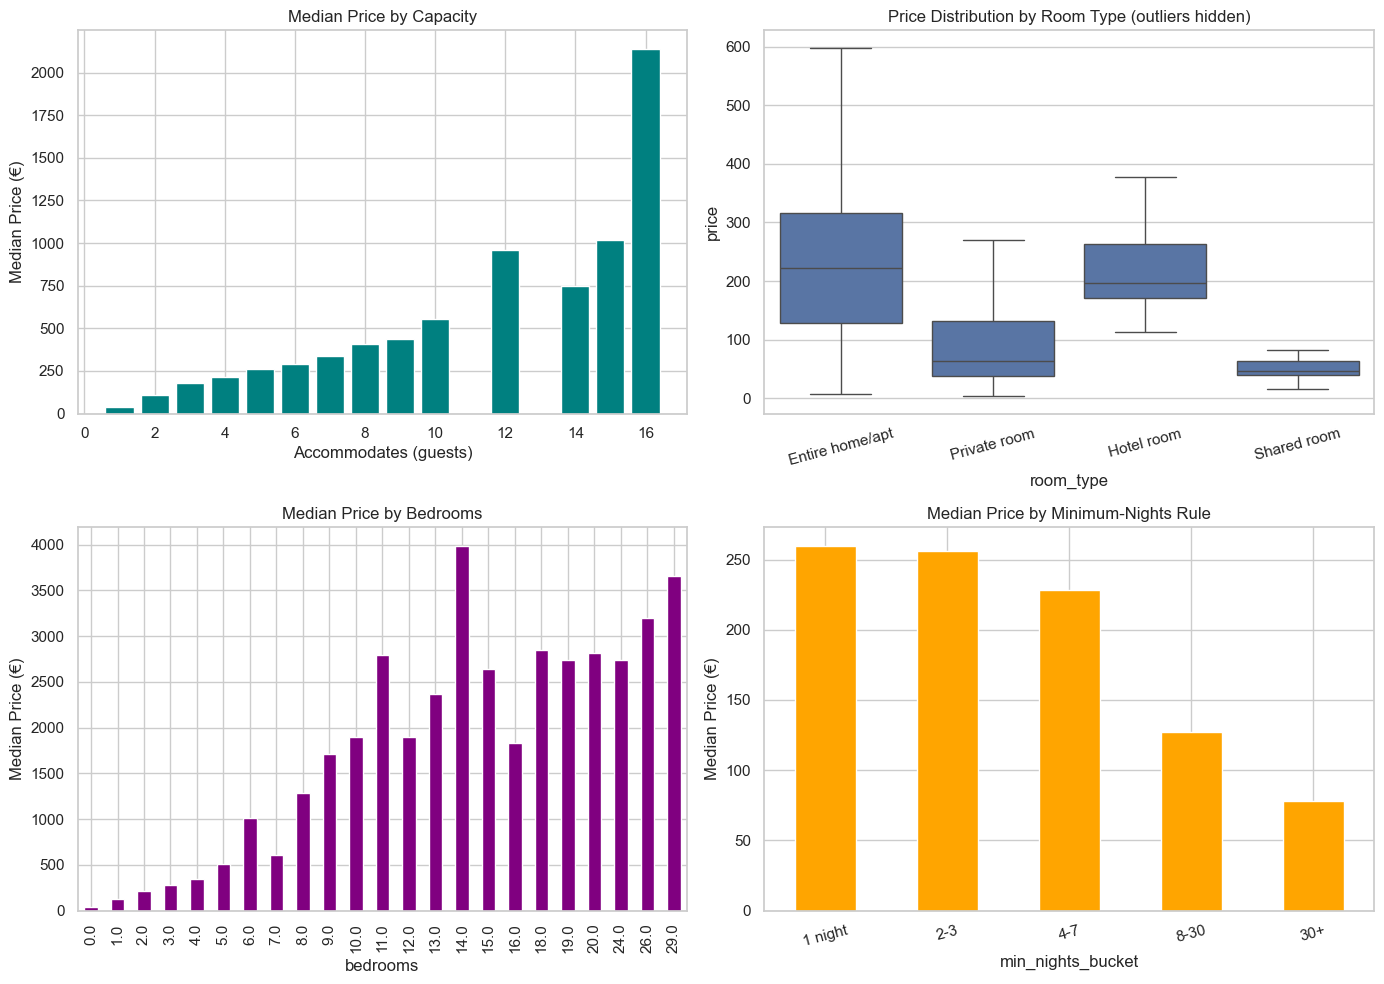


--- Superhost vs Non-Superhost Comparison ---


,listings,median_price,pct_entire_home,median_reviews
host_is_superhost,,,,
False,11274,161.0,67.0,4.0
True,3932,220.0,83.8,58.0


In [11]:
# Median price by accommodates
acc_price = listings.groupby('accommodates')['price'].agg(['median', 'count']).reset_index()
acc_price = acc_price[acc_price['count'] >= 20]  # only groups with 20+ listings

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# 1. Price vs accommodations
ax[0,0].bar(acc_price['accommodates'], acc_price['median'], color='teal')
ax[0,0].set_title('Median Price by Capacity')
ax[0,0].set_xlabel('Accommodates (guests)')
ax[0,0].set_ylabel('Median Price (€)')

# 2. Box plot by room type
sns.boxplot(data=listings, x='room_type', y='price', ax=ax[0,1], showfliers=False)
ax[0,1].set_title('Price Distribution by Room Type (outliers hidden)')
ax[0,1].tick_params(axis='x', rotation=15)

# 3. Median price by bedrooms
bed_price = listings.groupby('bedrooms')['price'].median()
bed_price.plot(kind='bar', ax=ax[1,0], color='purple')
ax[1,0].set_title('Median Price by Bedrooms')
ax[1,0].set_ylabel('Median Price (€)')

# 4. Median price by min nights (bucketed)
listings['min_nights_bucket'] = pd.cut(listings['minimum_nights'],
    bins=[0, 1, 3, 7, 30, 1000],
    labels=['1 night', '2-3', '4-7', '8-30', '30+'])
mn_price = listings.groupby('min_nights_bucket')['price'].median()
mn_price.plot(kind='bar', ax=ax[1,1], color='orange')
ax[1,1].set_title('Median Price by Minimum-Nights Rule')
ax[1,1].set_ylabel('Median Price (€)')
ax[1,1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# Superhost vs non-superhost comparison
print("\n--- Superhost vs Non-Superhost Comparison ---")
sh = listings.groupby('host_is_superhost').agg(
    listings=('id', 'count'),
    median_price=('price', 'median'),
    pct_entire_home=('room_type', lambda s: round((s=='Entire home/apt').mean()*100, 1)),
    median_reviews=('number_of_reviews', 'median')
).round(1)
display(sh)